### **การเขียนโปรแกรมด้วย Libraly NumPy สำหรับการจัดการข้อมูลเสียง**

---

**N1 (โค้ด) ตัดช่วงสัญญาณด้วย slicing**
  - **สร้างอะไร:** `sr = 22050`, สัญญาณ sine 440 Hz แอมพลิจูด 1 ยาว 1 วินาที (ใช้ `create_sin` ของเมื่อวานได้) แล้วเขียนฟังก์ชัน `get_segment(x, sr, start_s, end_s)` ที่คืนเฉพาะช่วงเวลาที่ขอ (ใบ้: แปลงวินาทีเป็น index แล้วต้องเป็น `int`)
  - **ทดสอบ:** ขอช่วง 0.50–0.52 s แล้ว print `.shape` และ `.dtype` ของผลลัพธ์ จากนั้นพล็อตช่วงนี้โดยแกน x เป็นมิลลิวินาทีที่ **เริ่มที่ 500 ms** ไม่ใช่ 0
  - **ทดลองเพิ่ม:** แก้ค่าในช่วงที่ตัดมา (เช่น `seg[:] = 0`) แล้วเช็คว่าสัญญาณต้นฉบับเปลี่ยนไหม
  - **ตอบ 2 ข้อ:** (1) ช่วง 20 ms ได้กี่ sample และคำนวณด้วยมือตรงกับ `.shape` ไหม (2) ต้นฉบับเปลี่ยนหรือไม่ เพราะอะไร (ค้นคำว่า NumPy view vs copy) และถ้าไม่อยากให้เปลี่ยนต้องใช้อะไร
  - **เสร็จเมื่อ:** shape ตรงกับที่คำนวณ, กราฟแกน x เริ่มที่ 500 ms และตอบครบ 2 ข้อ

---

**ตอบ**: 
1. จากการคำนวณ $n_{T_{sr}} = T_{sr} \times S_r$ \
เมื่อ $n_{T_{sr}}$ คือ จำนวน Sampling ในช่วงเวลาที่ต้องการ, $T_{sr}$ คือ ช่วงเวลาที่ต้องการ และ $S_r$ คือ อัตราการ Sampling\
จะได้ว่า $T_{sr} = 20 \times 10^{-3} s, S_r = 22050$ \
ดังนั้น $n_{T_{sr}} = 20 \times 10^{-3} \times 22050 = 441$ และตรงกับ `.shape` ซึ่งเท่ากับ 441

2. NumPy as view copy จะมีฟังก์ชัน 2 แบบคือ arr.view() และ arr.copy() ความแตกต่างระหว่าง view และ copy คือ view จะชี้ไปยัง array ต้นฉบับมาและเมื่อมีการแก้ไขจะกระทบกับ array หลัก ในขณะที่ copy เมื่อมีการแก้ไขจะไม่กระทบกับ array หลัก ถ้าต้องการไม่ให้เปลี่ยนให้ใช้ `array.copy()` พบว่าสัญญาณต้นฉบับมีการเปลี่ยนแปลง เพราะว่า slicing ของ NumPy `x[a:b]` จะ Return ออกมาเป็น view ถ้าต้องการให้สัญญาณต้นไม่มีการเปลี่ยนแปลงให้ใช้ `x[a:b].copy()`

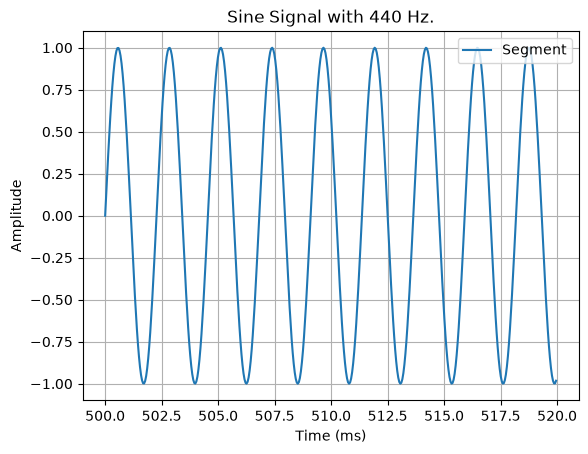

This is .shape of signal : (441,)
This is .dtype of signal : float64


In [1]:
# เขียนโปรแกรมสำหรับการสร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 440 Hz, แอมพลิจูดเท่ากับ 1, ระยะเวลา 1 วินาที
import numpy as np
import matplotlib.pyplot as plt

frequency = 440 # Frequency ความถี่
amplitude = 1   # Amplitude แอมพลิจูด
sr = 22050      # Sampling Rate 
start_s = 0.5
end_s = 0.52

t = np.arange(0, 1, 1/sr)

# ฟังก์ชันสำหรับสร้างสัญญาณ Sine
def create_sin(A, f, t, phase=0):
    signal = A * np.sin((2 * np.pi * f * t) + phase)
    return signal

# ฟังก์ชันสำหรับการเลือกช่วงมาพล็อตกราฟ
def get_segment(signal, sr, start_s, end_s):
    n_start = int(sr * start_s) # สร้างตัวแปร index ของ Sample ที่เป็นตัวแรกของสัญญาณ
    n_end = int(sr * end_s)     # สร้างตัวแปร index ของ Sample ที่เป็นตัวสุดท้ายของสัญญาณ

    # ทำการ Return ค่าหลายค่าออกมาเป็น Tuples
    return signal[n_start:n_end], n_start, n_end

sine_signal = create_sin(amplitude, frequency, t)   # สร้างสัญญาณ Sine
# ทำการเลือกช่วงสัญญาณที่ต้องการผ่านฟังก์ชัน get_segment จะได้เป็น Index เริ่มต้นและสุดท้ายของสัญญาณ
segment_signal, n_start, n_end = get_segment(sine_signal, sr, start_s, end_s)


fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal with 440 Hz.")
ax.plot(t[n_start:n_end]*1000, segment_signal, label="Segment")
ax.legend(loc="upper right")
plt.show()

# ทำการแสดงผลลัพธ์ของ Signal
print(f'This is .shape of signal : {segment_signal.shape}')
print(f'This is .dtype of signal : {segment_signal.dtype}')

In [2]:
# ทำการทดลองเกี่ยวกับ NumPy as view copy

# .copy()
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030].copy()
segment_signal[:] = 0 
print(f"This is original signal after .copy() : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after .copy() : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]


In [ ]:
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030]    # ชี้ไปยัง Array sine_signal 
segment_signal[:] = 0   # กำหนดค่าทุกค่าใน Array เท่ากับ 0
print(f"This is original signal after segment_signal[:] = 0 : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after segment_signal[:] = 0 : [0. 0. 0. 0. 0.]
